# STEP 1: DATASET LOADING

Load the AI4I 2020 Predictive Maintenance Dataset into pandas. Inspect the file, its dimensions, column names, data types, and sample records. The dataset will be used to develop a reconstruction-based anomaly detection system for industrial machine behaviour.

In [2]:
# STEP 1: LOAD THE AI4I 2020 DATASET

import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

warnings.filterwarnings("ignore")

from google.colab import files

uploaded = files.upload()

csv_files = [name for name in uploaded if name.lower().endswith(".csv")]

if not csv_files:
    raise ValueError("Please upload the AI4I 2020 CSV file.")

df = pd.read_csv(csv_files[0])

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

Saving ai4i2020.csv to ai4i2020.csv
Dataset loaded successfully.
Dataset shape: (10000, 14)

Column names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

First five records:


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0



Data types:


,Data Type
UDI,int64
Product ID,object
Type,object
Air temperature [K],float64
Process temperature [K],float64
Rotational speed [rpm],int64
Torque [Nm],float64
Tool wear [min],int64
Machine failure,int64
TWF,int64


# STEP 2: EXPLORATORY DATA ANALYSIS

Perform a preliminary audit of the dataset to understand data quality, missing values, duplicate records, sensor distributions, categorical variables, and machine-failure class imbalance. Generate visualisations to support the dataset description in the Phase I report.

Missing values per column:


,Missing Values
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


Duplicate rows: 0

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UDI,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
Product ID,10000,10000,L57163,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Machine failure,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
TWF,10000.0,NaN,NaN,NaN,0.0046,0.067671,0.0,0.0,0.0,0.0,1.0



Machine failure distribution:


,Count
Machine failure,
0,9661
1,339



Machine failure proportions:


,Percentage
Machine failure,
0,96.61
1,3.39


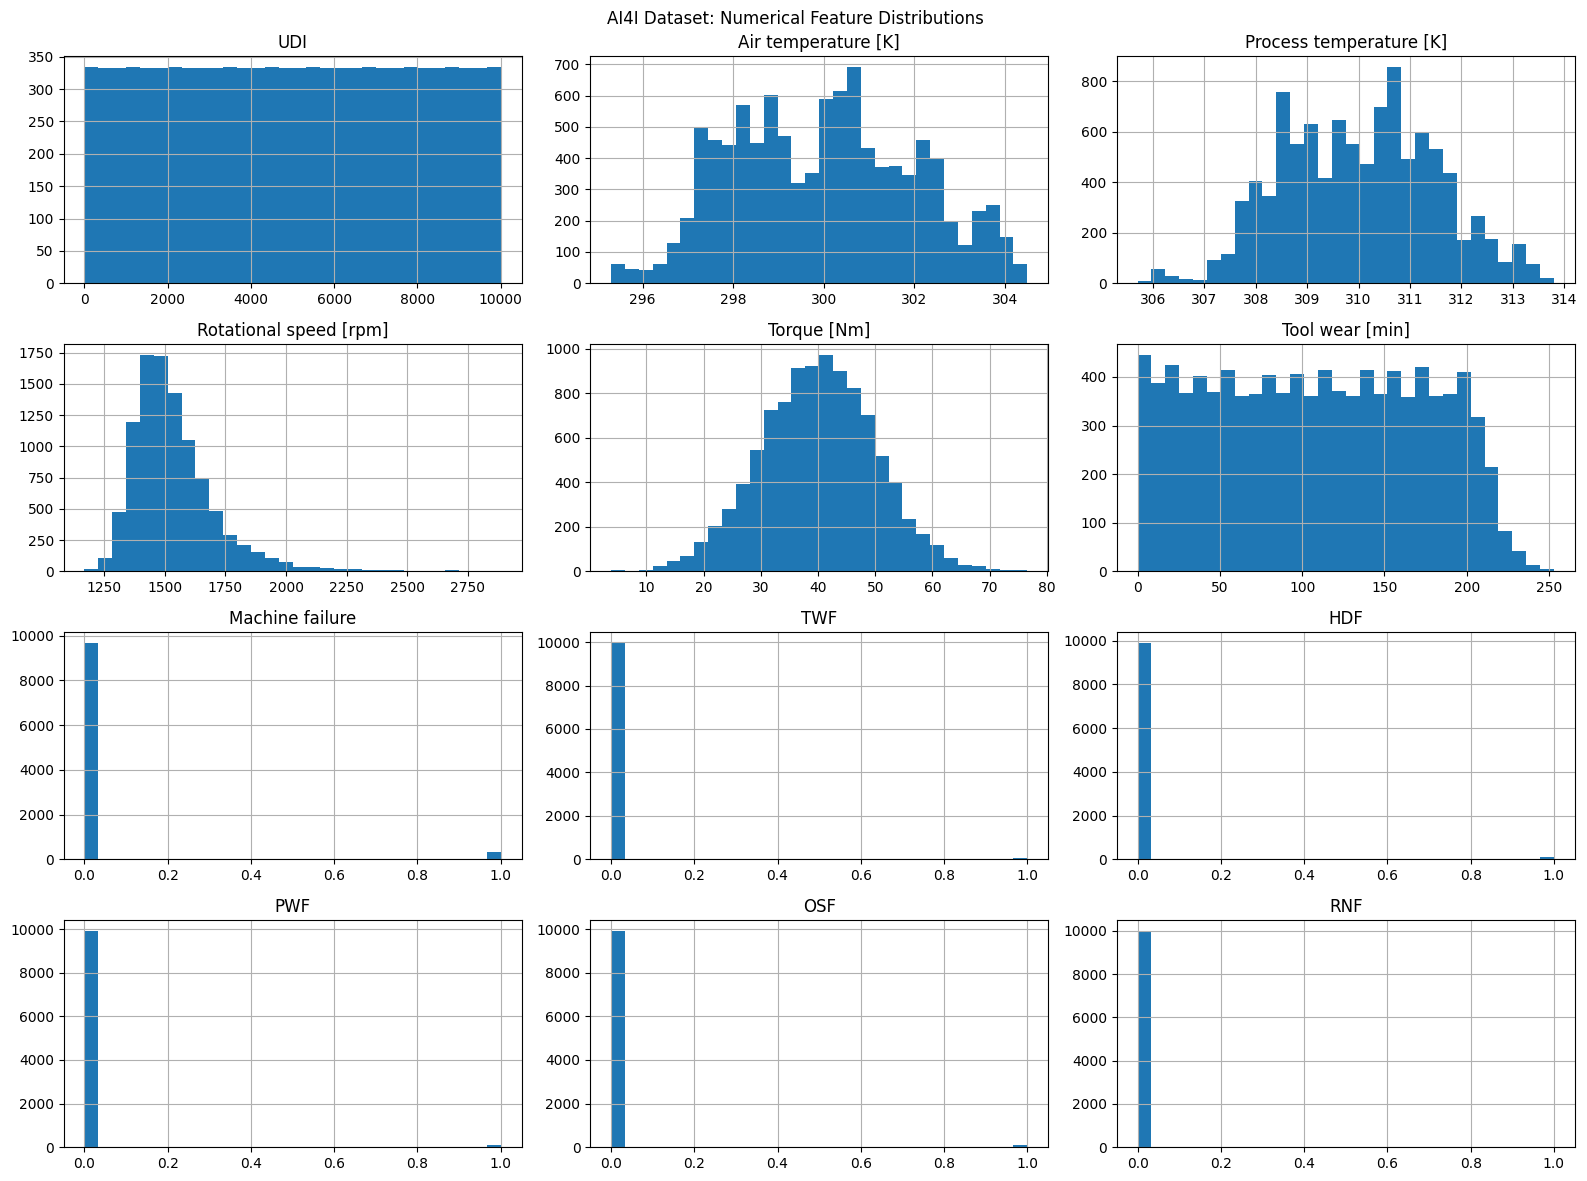

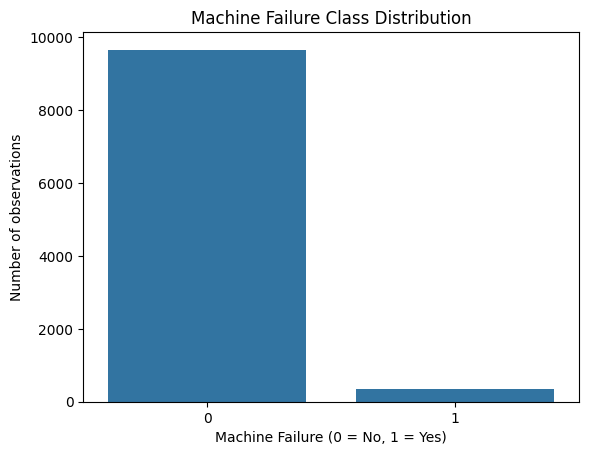

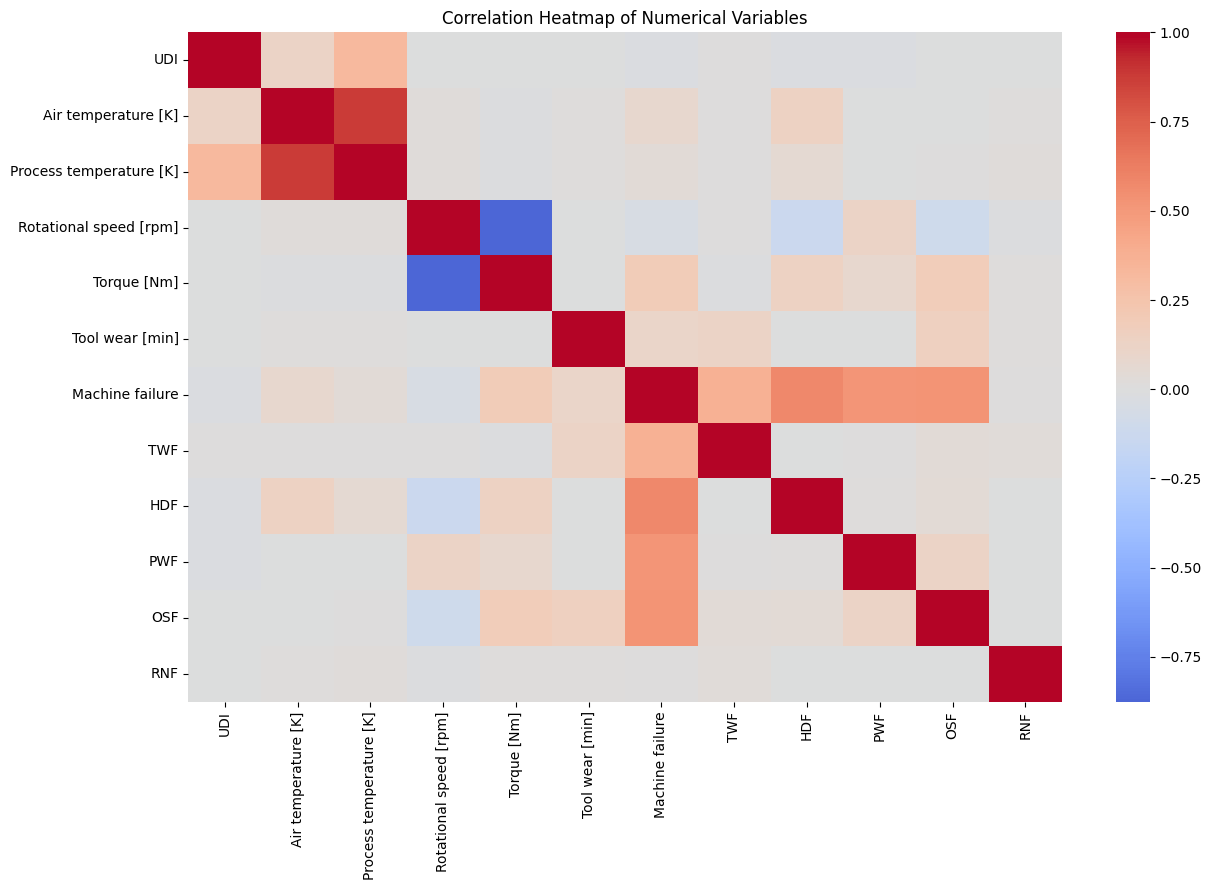

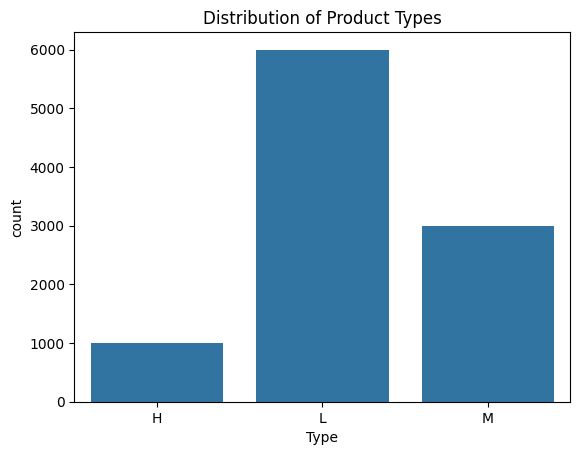

In [3]:
# STEP 2: DATASET AUDIT AND VISUALISATION

print("Missing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("Duplicate rows:", df.duplicated().sum())

print("\nDescriptive statistics:")
display(df.describe(include="all").T)

if "Machine failure" not in df.columns:
    raise ValueError(
        "Expected target column 'Machine failure' was not found. "
        "Inspect the actual CSV schema."
    )

print("\nMachine failure distribution:")
display(df["Machine failure"].value_counts(dropna=False).to_frame("Count"))

print("\nMachine failure proportions:")
display(
    (df["Machine failure"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage")
)

# Numeric feature distributions
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

df[numeric_columns].hist(
    figsize=(16, 12),
    bins=30
)

plt.suptitle("AI4I Dataset: Numerical Feature Distributions")
plt.tight_layout()
plt.show()

# Machine failure class balance
sns.countplot(data=df, x="Machine failure")
plt.title("Machine Failure Class Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of observations")
plt.show()

# Correlation heatmap
plt.figure(figsize=(13, 9))

sns.heatmap(
    df[numeric_columns].corr(),
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

# Categorical feature distribution
if "Type" in df.columns:
    sns.countplot(data=df, x="Type", order=sorted(df["Type"].dropna().unique()))
    plt.title("Distribution of Product Types")
    plt.show()

# STEP 3: PREPROCESSING AND DATA SPLITTING

Separate sensor inputs from failure-related targets. Exclude identifiers and all failure labels from the autoencoder inputs. Split the observations into training, validation, and test partitions using stratification where possible. Fit the categorical encoder and numerical scaler exclusively on the training partition. The autoencoder will subsequently train only on non-failure examples in that partition.

The dataset does not provide verified continuous timestamps for individual machines. Therefore, these partitions support observation-level anomaly evaluation, not genuine chronological early-warning validation.

In [4]:
# STEP 3: LEAKAGE-SAFE PREPROCESSING

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify columns from the actual dataset
target_col = "Machine failure"

identifier_candidates = ["UDI", "UID", "Product ID"]

identifier_cols = [
    col for col in identifier_candidates if col in df.columns
]

failure_target_cols = [
    col for col in ["Machine failure", "TWF", "HDF", "PWF", "OSF", "RNF"]
    if col in df.columns
]

# Retain only records with a valid primary target
valid_mask = df[target_col].notna()
data = df.loc[valid_mask].copy()

# Separate ground-truth labels from input features
y = data[target_col].astype(int)

excluded_cols = set(identifier_cols + failure_target_cols)

feature_cols = [
    col for col in data.columns if col not in excluded_cols
]

X = data[feature_cols].copy()

# Infer categorical and numerical input columns
categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

if not numeric_cols and not categorical_cols:
    raise ValueError("No usable sensor features were identified.")

print("Excluded identifier columns:", identifier_cols)
print("Excluded target columns:", failure_target_cols)
print("Numerical input features:", numeric_cols)
print("Categorical input features:", categorical_cols)

# Stratified train/test split, then training/validation split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_train_raw, y_train,
    test_size=0.25,
    random_state=SEED,
    stratify=y_train
)

# Fit preprocessing ONLY on training observations
transformers = []

if numeric_cols:
    transformers.append(
        ("numeric", StandardScaler(), numeric_cols)
    )

if categorical_cols:
    transformers.append(
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        )
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

X_train_all = preprocessor.fit_transform(X_train_raw)
X_val = preprocessor.transform(X_val_raw)
X_test = preprocessor.transform(X_test_raw)

# Convert sparse matrices if necessary
if hasattr(X_train_all, "toarray"):
    X_train_all = X_train_all.toarray()

if hasattr(X_val, "toarray"):
    X_val = X_val.toarray()

if hasattr(X_test, "toarray"):
    X_test = X_test.toarray()

X_train_all = np.asarray(X_train_all, dtype=np.float32)
X_val = np.asarray(X_val, dtype=np.float32)
X_test = np.asarray(X_test, dtype=np.float32)

# Autoencoder training data: normal observations only
normal_train_mask = (y_train.to_numpy() == 0)
X_train_normal = X_train_all[normal_train_mask]

if len(X_train_normal) == 0:
    raise ValueError("No normal training observations are available.")

# Extract original record indices for traceability
train_indices = X_train_raw.index.to_numpy()
val_indices = X_val_raw.index.to_numpy()
test_indices = X_test_raw.index.to_numpy()

print("\nSplit sizes:")
print("Training partition:", X_train_all.shape)
print("Normal training examples:", X_train_normal.shape)
print("Validation partition:", X_val.shape)
print("Test partition:", X_test.shape)

print("\nNormal training failure-label counts:")
print(y_train.value_counts())

print("\nValidation failure-label counts:")
print(y_val.value_counts())

print("\nTest failure-label counts:")
print(y_test.value_counts())

print("\nPreprocessing completed.")

Excluded identifier columns: ['UDI', 'Product ID']
Excluded target columns: ['Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
Numerical input features: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Categorical input features: ['Type']

Split sizes:
Training partition: (6000, 8)
Normal training examples: (5797, 8)
Validation partition: (2000, 8)
Test partition: (2000, 8)

Normal training failure-label counts:
Machine failure
0    5797
1     203
Name: count, dtype: int64

Validation failure-label counts:
Machine failure
0    1932
1      68
Name: count, dtype: int64

Test failure-label counts:
Machine failure
0    1932
1      68
Name: count, dtype: int64

Preprocessing completed.


# STEP 4: AUTOENCODER TRAINING

Build a feed-forward autoencoder that learns to reconstruct normal machine operating patterns. The encoder compresses the input into a lower-dimensional latent representation, and the decoder reconstructs the original features. Train the model using normal training observations and monitor reconstruction loss on normal validation observations. Save the trained model and training history.

Epoch 1/100
91/91 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.6884 - val_loss: 0.5681 - learning_rate: 0.0010
Epoch 2/100
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4685 - val_loss: 0.3953 - learning_rate: 0.0010
Epoch 3/100
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3428 - val_loss: 0.3052 - learning_rate: 0.0010
Epoch 4/100
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2799 - val_loss: 0.2596 - learning_rate: 0.0010
Epoch 5/100
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2470 - val_loss: 0.2348 - learning_rate: 0.0010
Epoch 6/100
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2297 - val_loss: 0.2237 - learning_rate: 0.0010
Epoch 7/100
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2202 - val_loss: 0.2156 - learning_rate: 0.0010
Epoch 8/100
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2109 - val_loss: 0.2038 - learning_rate: 0.0010
Epoch 9/100
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1883 - val_loss: 0.1678 - learning_rate: 0.0010
Epoch 10/100
91/91 

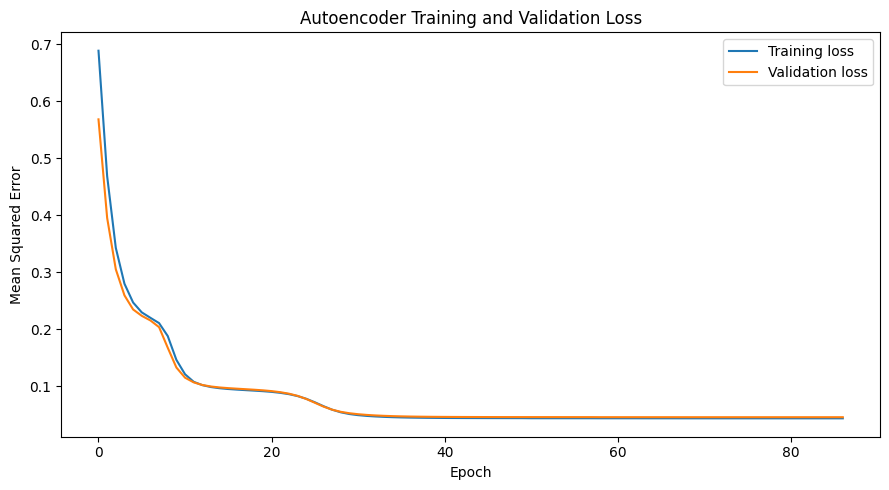

In [5]:
# STEP 4: BUILD AND TRAIN THE AUTOENCODER

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.keras.utils.set_random_seed(SEED)

input_dim = X_train_normal.shape[1]

if input_dim < 2:
    raise ValueError("The autoencoder requires at least two input features.")

latent_dim = max(2, min(8, input_dim // 2))

inputs = layers.Input(shape=(input_dim,), name="sensor_input")

# Encoder
x = layers.Dense(
    max(latent_dim * 2, input_dim // 2),
    activation="relu"
)(inputs)

latent = layers.Dense(
    latent_dim,
    activation="relu",
    name="latent_representation"
)(x)

# Decoder
x = layers.Dense(
    max(latent_dim * 2, input_dim // 2),
    activation="relu"
)(latent)

outputs = layers.Dense(
    input_dim,
    activation="linear",
    name="reconstructed_input"
)(x)

autoencoder = Model(inputs, outputs, name="MachineBehaviorAutoencoder")

autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

# Normal validation examples only
normal_val_mask = (y_val.to_numpy() == 0)
X_val_normal = X_val[normal_val_mask]

if len(X_val_normal) == 0:
    raise ValueError("No normal validation examples are available.")

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6
    )
]

history = autoencoder.fit(
    X_train_normal,
    X_train_normal,
    validation_data=(X_val_normal, X_val_normal),
    epochs=100,
    batch_size=64,
    shuffle=True,
    callbacks=callbacks,
    verbose=1
)

os.makedirs("outputs/models", exist_ok=True)
os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("outputs/tables", exist_ok=True)
os.makedirs("outputs/metrics", exist_ok=True)

autoencoder.save("outputs/models/autoencoder.keras")

print("\nAutoencoder training completed.")
print("Input features:", input_dim)
print("Latent dimensions:", latent_dim)
print("Epochs executed:", len(history.history["loss"]))
print("Final training loss:", history.history["loss"][-1])
print("Final validation loss:", history.history["val_loss"][-1])

# Plot loss curves
plt.figure(figsize=(9, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Autoencoder Training and Validation Loss")
plt.legend()
plt.tight_layout()
plt.savefig(
    "outputs/figures/autoencoder_training_loss.png",
    dpi=300
)
plt.show()

# STEP 5: RECONSTRUCTION ERROR AND ANOMALY SCORING

Use the trained autoencoder to reconstruct validation and test observations. Calculate mean squared reconstruction error for each observation. Select the anomaly threshold using only reconstruction errors from normal validation observations. Apply the fixed threshold to the held-out test partition and save observation-level anomaly scores.

The machine-failure label will be used only for post-hoc evaluation. It is not a perfect ground-truth label for all anomalous behaviour, so anomaly detection performance and failure-label detection performance must be interpreted separately.

Threshold percentile: 95
Selected anomaly threshold: 0.1704111248254776
Mean normal validation error: 0.045977812
Median normal validation error: 0.024385408
Test observations flagged as anomalous: 102
Percentage of test observations flagged: 5.1 %


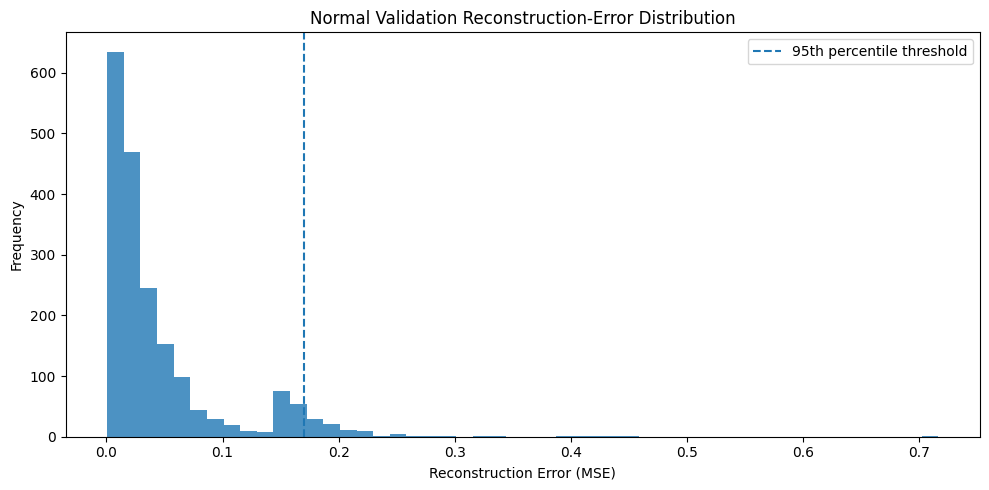

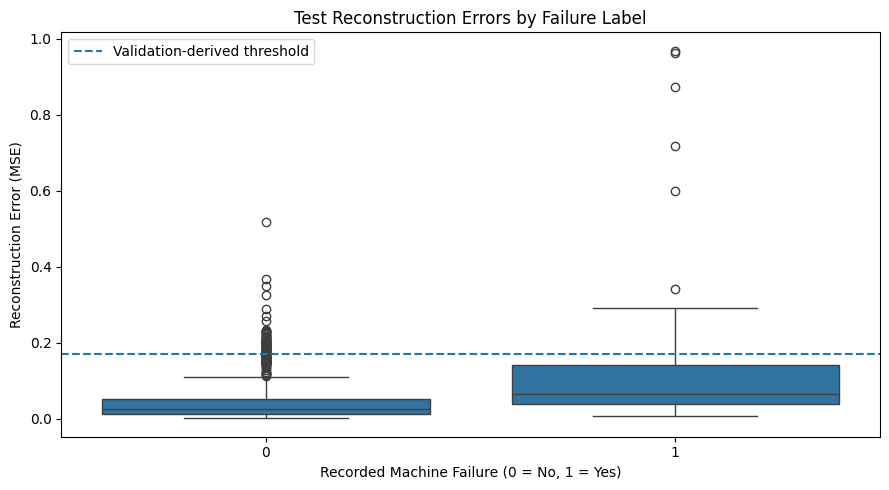


Sample anomaly scores:


,row_index,reconstruction_error,anomaly_threshold,predicted_anomaly,machine_failure
0,2997,0.100101,0.170411,0,0
1,4871,0.005540,0.170411,0,0
2,3858,0.007701,0.170411,0,0
3,951,0.166792,0.170411,0,0
4,6463,0.217653,0.170411,1,0
5,3264,0.167577,0.170411,0,0
6,4508,0.094218,0.170411,0,0
7,2100,0.010225,0.170411,0,0
8,7885,0.090557,0.170411,0,0
9,2421,0.348287,0.170411,1,0


In [6]:
# STEP 5: RECONSTRUCTION ERRORS AND ANOMALY THRESHOLD

def reconstruction_errors(model, X):
    reconstructed = model.predict(X, verbose=0)
    return np.mean(np.square(X - reconstructed), axis=1)

val_errors = reconstruction_errors(autoencoder, X_val)
test_errors = reconstruction_errors(autoencoder, X_test)

# Threshold derived only from normal validation observations
normal_val_errors = val_errors[normal_val_mask]

THRESHOLD_PERCENTILE = 95

threshold = float(
    np.percentile(normal_val_errors, THRESHOLD_PERCENTILE)
)

val_anomaly_flags = val_errors > threshold
test_anomaly_flags = test_errors > threshold

print("Threshold percentile:", THRESHOLD_PERCENTILE)
print("Selected anomaly threshold:", threshold)
print("Mean normal validation error:", normal_val_errors.mean())
print("Median normal validation error:", np.median(normal_val_errors))
print("Test observations flagged as anomalous:", test_anomaly_flags.sum())
print(
    "Percentage of test observations flagged:",
    round(100 * test_anomaly_flags.mean(), 2), "%"
)

# Validation error distribution
plt.figure(figsize=(10, 5))
plt.hist(normal_val_errors, bins=50, alpha=0.8)
plt.axvline(
    threshold,
    linestyle="--",
    label=f"{THRESHOLD_PERCENTILE}th percentile threshold"
)
plt.xlabel("Reconstruction Error (MSE)")
plt.ylabel("Frequency")
plt.title("Normal Validation Reconstruction-Error Distribution")
plt.legend()
plt.tight_layout()
plt.savefig(
    "outputs/figures/validation_error_distribution.png",
    dpi=300
)
plt.show()

# Test scores by recorded machine-failure label
test_score_df = pd.DataFrame({
    "row_index": test_indices,
    "reconstruction_error": test_errors,
    "anomaly_threshold": threshold,
    "predicted_anomaly": test_anomaly_flags.astype(int),
    "machine_failure": y_test.to_numpy()
})

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=test_score_df,
    x="machine_failure",
    y="reconstruction_error"
)
plt.axhline(
    threshold,
    linestyle="--",
    label="Validation-derived threshold"
)
plt.xlabel("Recorded Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Reconstruction Error (MSE)")
plt.title("Test Reconstruction Errors by Failure Label")
plt.legend()
plt.tight_layout()
plt.savefig(
    "outputs/figures/test_error_by_failure.png",
    dpi=300
)
plt.show()

test_score_df.to_csv(
    "outputs/tables/test_anomaly_scores.csv",
    index=False
)

print("\nSample anomaly scores:")
display(test_score_df.head(10))

# STEP 6: HELD-OUT EVALUATION

Evaluate the threshold-based detector on the held-out test partition. Report precision, recall, F1-score, confusion matrix, and precision-recall AUC where defined. Because the available labels represent recorded machine failures rather than independently verified anomalies, clearly describe these as failure-label proxy evaluation metrics, not definitive measures of all behavioural anomalies.

Evaluation against recorded machine-failure labels
Precision: 0.1471
Recall: 0.2206
F1-score: 0.1765
PR-AUC / Average Precision: 0.17834321380610285

Classification report:
              precision    recall  f1-score   support

           0       0.97      0.95      0.96      1932
           1       0.15      0.22      0.18        68

    accuracy                           0.93      2000
   macro avg       0.56      0.59      0.57      2000
weighted avg       0.94      0.93      0.94      2000



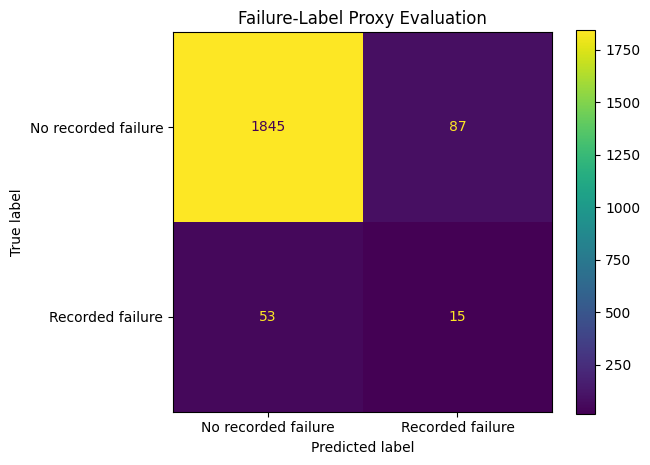

,threshold_percentile,threshold,precision,recall,f1_score,pr_auc_average_precision,test_observations,test_anomalies_flagged,random_seed
0,95,0.170411,0.147059,0.220588,0.176471,0.178343,2000,102,42


In [7]:
# STEP 6: EVALUATION METRICS

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    ConfusionMatrixDisplay
)

y_test_array = y_test.to_numpy()
y_pred = test_anomaly_flags.astype(int)

precision = precision_score(
    y_test_array, y_pred, zero_division=0
)

recall = recall_score(
    y_test_array, y_pred, zero_division=0
)

f1 = f1_score(
    y_test_array, y_pred, zero_division=0
)

if len(np.unique(y_test_array)) == 2:
    pr_auc = average_precision_score(
        y_test_array,
        test_errors
    )
else:
    pr_auc = np.nan

cm = confusion_matrix(
    y_test_array,
    y_pred,
    labels=[0, 1]
)

print("Evaluation against recorded machine-failure labels")
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))
print("PR-AUC / Average Precision:", pr_auc)

print("\nClassification report:")
print(
    classification_report(
        y_test_array,
        y_pred,
        zero_division=0
    )
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No recorded failure", "Recorded failure"]
).plot()

plt.title("Failure-Label Proxy Evaluation")
plt.tight_layout()
plt.savefig(
    "outputs/figures/confusion_matrix.png",
    dpi=300
)
plt.show()

metrics = pd.DataFrame([{
    "threshold_percentile": THRESHOLD_PERCENTILE,
    "threshold": threshold,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "pr_auc_average_precision": pr_auc,
    "test_observations": len(y_test_array),
    "test_anomalies_flagged": int(y_pred.sum()),
    "random_seed": SEED
}])

metrics.to_csv(
    "outputs/metrics/evaluation_metrics.csv",
    index=False
)

display(metrics)

# STEP 7: TEMPORAL DRIFT DETECTION

Implement rolling-window analysis of anomaly scores to identify sustained deviations from normal behaviour. Since the AI4I dataset does not provide verified chronological machine telemetry, first demonstrate the score analysis on the ordered test partition as an exploratory exercise. Then conduct a controlled experiment by injecting an artificial distribution shift into normal validation observations.

The controlled experiment demonstrates whether the anomaly-scoring pipeline responds to an introduced change. It does not establish real-world predictive lead time or prove that actual machine failures can be predicted in advance.

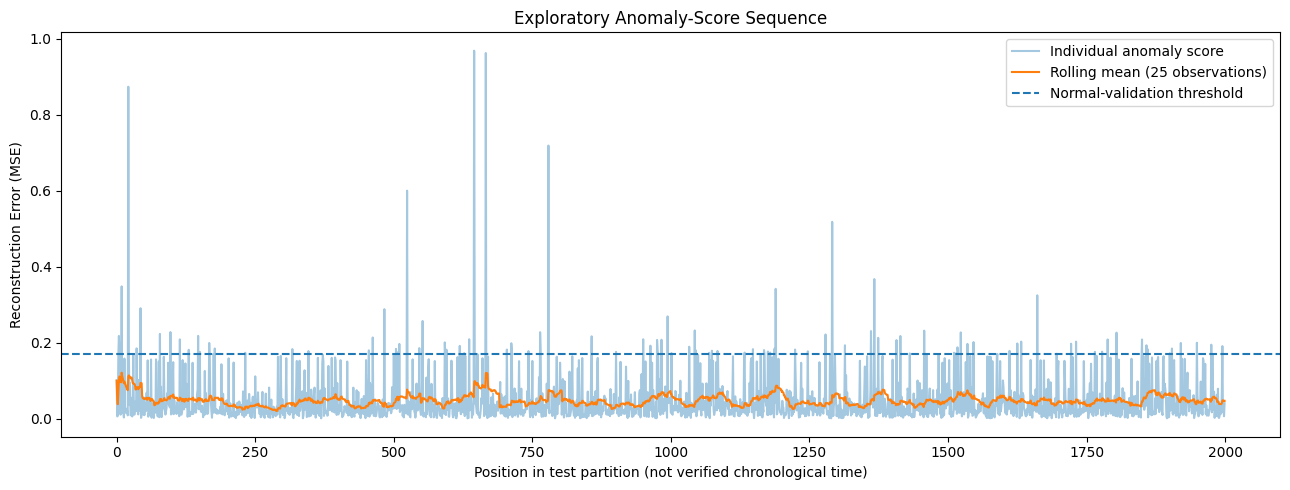

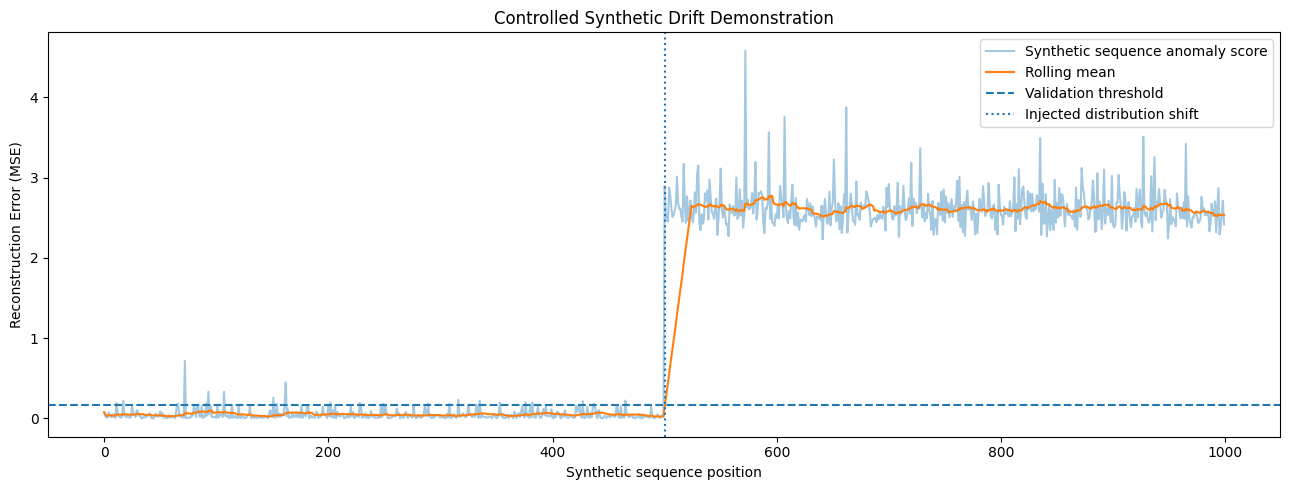

Mean baseline reconstruction error: 0.048248
Mean shifted reconstruction error: 2.61858
This is a controlled synthetic experiment, not real machine-time evidence.


In [8]:
# STEP 7: ROLLING-WINDOW ANALYSIS

ROLLING_WINDOW = 25

# Exploratory analysis only: test row order is not verified machine time
rolling_scores = pd.Series(test_errors).rolling(
    window=ROLLING_WINDOW,
    min_periods=1
).mean()

plt.figure(figsize=(13, 5))
plt.plot(test_errors, alpha=0.4, label="Individual anomaly score")
plt.plot(
    rolling_scores,
    label=f"Rolling mean ({ROLLING_WINDOW} observations)"
)
plt.axhline(
    threshold,
    linestyle="--",
    label="Normal-validation threshold"
)
plt.xlabel("Position in test partition (not verified chronological time)")
plt.ylabel("Reconstruction Error (MSE)")
plt.title("Exploratory Anomaly-Score Sequence")
plt.legend()
plt.tight_layout()
plt.savefig(
    "outputs/figures/exploratory_rolling_scores.png",
    dpi=300
)
plt.show()

# Controlled synthetic distribution-shift experiment
rng = np.random.default_rng(SEED)

n_base = min(500, len(X_val_normal))

if n_base < 50:
    raise ValueError(
        "Insufficient normal validation observations for the synthetic experiment."
    )

base = X_val_normal[:n_base].copy()

# Create an artificial shift in the scaled feature space
shifted = base + 1.5

synthetic_sequence = np.vstack([base, shifted])

synthetic_errors = reconstruction_errors(
    autoencoder,
    synthetic_sequence
)

synthetic_rolling = pd.Series(synthetic_errors).rolling(
    ROLLING_WINDOW,
    min_periods=1
).mean()

change_point = len(base)

plt.figure(figsize=(13, 5))
plt.plot(
    synthetic_errors,
    alpha=0.4,
    label="Synthetic sequence anomaly score"
)
plt.plot(
    synthetic_rolling,
    label="Rolling mean"
)
plt.axhline(
    threshold,
    linestyle="--",
    label="Validation threshold"
)
plt.axvline(
    change_point,
    linestyle=":",
    label="Injected distribution shift"
)
plt.xlabel("Synthetic sequence position")
plt.ylabel("Reconstruction Error (MSE)")
plt.title("Controlled Synthetic Drift Demonstration")
plt.legend()
plt.tight_layout()
plt.savefig(
    "outputs/figures/synthetic_drift_experiment.png",
    dpi=300
)
plt.show()

synthetic_results = pd.DataFrame({
    "sequence_position": np.arange(len(synthetic_errors)),
    "sequence_segment": (
        ["baseline"] * len(base) +
        ["artificial_shift"] * len(shifted)
    ),
    "reconstruction_error": synthetic_errors,
    "rolling_mean_error": synthetic_rolling.to_numpy(),
    "anomaly_threshold": threshold
})

synthetic_results.to_csv(
    "outputs/tables/synthetic_drift_results.csv",
    index=False
)

print("Mean baseline reconstruction error:",
      round(float(synthetic_errors[:change_point].mean()), 6))

print("Mean shifted reconstruction error:",
      round(float(synthetic_errors[change_point:].mean()), 6))

print("This is a controlled synthetic experiment, not real machine-time evidence.")

# STEP 8: EXPORT PROJECT ARTIFACTS

Organise and export the outputs needed for the Phase I implementation report, including the trained autoencoder, measured metrics, observation-level anomaly scores, controlled drift experiment results, and saved visualisations. Create a ZIP archive that can be downloaded from Google Colab and used to support the report with actual evidence.

In [9]:
# STEP 8: SAVE AND DOWNLOAD ALL PROJECT OUTPUTS

import json
import zipfile

# Save the preprocessing object
import joblib

joblib.dump(
    preprocessor,
    "outputs/models/preprocessor.joblib"
)

# Save experiment configuration
config = {
    "random_seed": SEED,
    "threshold_percentile": THRESHOLD_PERCENTILE,
    "selected_threshold": float(threshold),
    "rolling_window": ROLLING_WINDOW,
    "input_features": feature_cols,
    "numeric_features": numeric_cols,
    "categorical_features": categorical_cols,
    "excluded_identifiers": identifier_cols,
    "excluded_targets": failure_target_cols,
    "train_observations": int(len(X_train_all)),
    "normal_train_observations": int(len(X_train_normal)),
    "validation_observations": int(len(X_val)),
    "test_observations": int(len(X_test)),
    "temporal_limitation": (
        "AI4I CSV does not provide verified continuous chronological "
        "telemetry for individual machines."
    )
}

with open("outputs/metrics/experiment_config.json", "w") as f:
    json.dump(config, f, indent=2)

# Save training history
pd.DataFrame(history.history).to_csv(
    "outputs/tables/training_history.csv",
    index_label="epoch"
)

# Save a concise execution summary
summary = {
    "dataset_rows_loaded": int(len(df)),
    "dataset_columns_loaded": int(df.shape[1]),
    "input_feature_count": int(input_dim),
    "epochs_completed": int(len(history.history["loss"])),
    "final_training_loss": float(history.history["loss"][-1]),
    "final_validation_loss": float(history.history["val_loss"][-1]),
    "anomaly_threshold": float(threshold),
    "test_precision_vs_failure_labels": float(precision),
    "test_recall_vs_failure_labels": float(recall),
    "test_f1_vs_failure_labels": float(f1),
    "test_pr_auc_vs_failure_labels": (
        float(pr_auc) if np.isfinite(pr_auc) else None
    ),
    "note": (
        "Metrics compare anomaly flags with recorded failure labels. "
        "They are not proof of early failure prediction."
    )
}

with open("outputs/metrics/execution_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

# Package outputs
zip_path = "Phase_I_Project_Outputs.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for root, dirs, filenames in os.walk("outputs"):
        for filename in filenames:
            full_path = os.path.join(root, filename)
            zf.write(full_path, arcname=full_path)

print("Output files created:")
for root, dirs, filenames in os.walk("outputs"):
    for filename in filenames:
        print(os.path.join(root, filename))

print("\nExecution summary:")
display(pd.DataFrame([summary]).T.rename(columns={0: "Value"}))

files.download(zip_path)

Output files created:
outputs/models/autoencoder.keras
outputs/models/preprocessor.joblib
outputs/metrics/experiment_config.json
outputs/metrics/evaluation_metrics.csv
outputs/metrics/execution_summary.json
outputs/tables/test_anomaly_scores.csv
outputs/tables/training_history.csv
outputs/tables/synthetic_drift_results.csv
outputs/figures/confusion_matrix.png
outputs/figures/test_error_by_failure.png
outputs/figures/validation_error_distribution.png
outputs/figures/autoencoder_training_loss.png
outputs/figures/synthetic_drift_experiment.png
outputs/figures/exploratory_rolling_scores.png

Execution summary:


,Value
dataset_rows_loaded,10000
dataset_columns_loaded,14
input_feature_count,8
epochs_completed,87
final_training_loss,0.043982
final_validation_loss,0.045978
anomaly_threshold,0.170411
test_precision_vs_failure_labels,0.147059
test_recall_vs_failure_labels,0.220588
test_f1_vs_failure_labels,0.176471


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 9: Baseline Model Comparison

In this step, we compare the autoencoder with three established anomaly-detection algorithms: Isolation Forest, Local Outlier Factor (LOF), and One-Class SVM. The purpose is to determine whether a neural-network-based approach offers an advantage over simpler methods.

All models will be trained using normal training records. Their anomaly scores will be calibrated using normal validation records, and their predictions will then be evaluated against the machine-failure labels in the test set. We will compare precision, recall, F1-score, and average precision instead of relying only on accuracy.

The failure labels are used as a proxy for evaluation. An unusual sensor pattern does not necessarily mean that a machine has failed.

In [10]:
# Compare baseline anomaly-detection models

import numpy as np
import pandas as pd

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, confusion_matrix
)

# Required existing variables:
# X_train_normal: normal training records only
# X_val_normal: normal validation records only
# X_test: all test features
# y_test: test labels (0 = no recorded failure, 1 = failure)

X_normal = np.asarray(X_train_normal)
X_val_normal_arr = np.asarray(X_val_normal)
X_test_arr = np.asarray(X_test)
y_test_array = np.asarray(y_test).ravel().astype(int)

models = {
    "Isolation Forest": IsolationForest(
        n_estimators=200,
        contamination="auto",
        random_state=42,
        n_jobs=-1
    ),
    "Local Outlier Factor": LocalOutlierFactor(
        n_neighbors=20,
        novelty=True,
        contamination="auto",
        n_jobs=-1
    ),
    "One-Class SVM": OneClassSVM(
        kernel="rbf",
        gamma="scale",
        nu=0.05
    )
}

results = []
baseline_scores = {}

for name, model in models.items():
    model.fit(X_normal)

    # Higher scores must mean more anomalous.
    val_scores = -model.score_samples(X_val_normal_arr)
    test_scores = -model.score_samples(X_test_arr)

    # Calibrate each model using normal validation records.
    model_threshold = np.percentile(val_scores, 95)
    predictions = (test_scores > model_threshold).astype(int)

    baseline_scores[name] = {
        "model": model,
        "threshold": float(model_threshold),
        "test_scores": test_scores,
        "predictions": predictions
    }

    results.append({
        "Model": name,
        "Threshold": model_threshold,
        "Precision": precision_score(
            y_test_array, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test_array, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test_array, predictions, zero_division=0
        ),
        "Average Precision": average_precision_score(
            y_test_array, test_scores
        ),
        "Confusion Matrix": confusion_matrix(
            y_test_array, predictions
        ).tolist()
    })

baseline_results = pd.DataFrame(results)
display(
    baseline_results.drop(columns=["Confusion Matrix"])
    .round(4)
    .sort_values("F1-score", ascending=False)
)

print("\nConfusion matrices:")
for row in results:
    print(f"\n{row["Model"]}:")
    print(np.array(row["Confusion Matrix"]))


,Model,Threshold,Precision,Recall,F1-score,Average Precision
1,Local Outlier Factor,1.1903,0.2619,0.4853,0.3402,0.3205
2,One-Class SVM,-27.3390,0.2520,0.4559,0.3246,0.2854
0,Isolation Forest,0.5907,0.1200,0.1765,0.1429,0.0963



Confusion matrices:

Isolation Forest:
[[1844   88]
 [  56   12]]

Local Outlier Factor:
[[1839   93]
 [  35   33]]

One-Class SVM:
[[1840   92]
 [  37   31]]


## Step 10: Autoencoder Threshold Sensitivity Analysis

The autoencoder identifies unusual records by comparing reconstruction errors with a threshold. A low threshold may detect more unusual records but can also produce more false alarms. A high threshold may reduce false alarms while missing more failures.

In this step, we examine multiple thresholds derived from the reconstruction errors of normal validation records. We then evaluate the resulting predictions against the test failure labels. The test results are used for analysis only; the final threshold should be selected using validation data, not by optimizing performance on the test set.

In [12]:

# STEP 10: Autoencoder threshold sensitivity analysis

import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, confusion_matrix
)

# Reuse variable names confirmed by your Step 9 notebook.
X_reference = np.asarray(X_val_normal, dtype=np.float32)
X_test_arr = np.asarray(X_test, dtype=np.float32)
y_test_arr = np.asarray(y_test_array).ravel().astype(int)

# Compute reconstruction errors.
def get_reconstruction_errors(model, X):
    reconstructed = model.predict(X, verbose=0)
    return np.mean(np.square(X - reconstructed), axis=1)

reference_errors = get_reconstruction_errors(
    autoencoder, X_reference
)
test_errors = get_reconstruction_errors(
    autoencoder, X_test_arr
)

# Candidate thresholds calibrated only on normal validation records.
percentiles = [90, 92, 95, 97, 98, 99]
candidate_thresholds = np.percentile(
    reference_errors, percentiles
)

threshold_rows = []

for percentile, candidate in zip(
    percentiles, candidate_thresholds
):
    predictions = (test_errors > candidate).astype(int)

    threshold_rows.append({
        "Validation_Percentile": percentile,
        "Threshold": float(candidate),
        "Precision": precision_score(
            y_test_arr, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test_arr, predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test_arr, predictions, zero_division=0
        ),
        "Average_Precision": average_precision_score(
            y_test_arr, test_errors
        ),
        "Confusion_Matrix": confusion_matrix(
            y_test_arr, predictions
        ).tolist()
    })

threshold_analysis = pd.DataFrame(threshold_rows)

display(
    threshold_analysis.drop(
        columns=["Confusion_Matrix"]
    ).round(4)
)

print("\nConfusion matrices for each threshold:")
for row in threshold_rows:
    print(
        f"\nValidation percentile: "
        f"{row['Validation_Percentile']}"
    )
    print(np.array(row["Confusion_Matrix"]))

threshold_analysis.to_csv(
    "/content/step10_threshold_analysis.csv",
    index=False
)
print("Original threshold:", threshold)

print("\nCandidate thresholds:")
print(
    threshold_analysis[
        ["Validation_Percentile", "Threshold",
         "Precision", "Recall", "F1_Score"]
    ].round(4).to_string(index=False)
)

original_95_threshold = threshold_analysis.loc[
    threshold_analysis["Validation_Percentile"] == 95,
    "Threshold"
].iloc[0]

print("\n95th-percentile threshold:", original_95_threshold)

,Validation_Percentile,Threshold,Precision,Recall,F1_Score,Average_Precision
0,90,0.1486,0.0802,0.2500,0.1214,0.1783
1,92,0.1545,0.0920,0.2353,0.1322,0.1783
2,95,0.1704,0.1471,0.2206,0.1765,0.1783
3,97,0.1873,0.2105,0.1765,0.1920,0.1783
4,98,0.2009,0.2250,0.1324,0.1667,0.1783
5,99,0.2217,0.3636,0.1176,0.1778,0.1783



Confusion matrices for each threshold:

Validation percentile: 90
[[1737  195]
 [  51   17]]

Validation percentile: 92
[[1774  158]
 [  52   16]]

Validation percentile: 95
[[1845   87]
 [  53   15]]

Validation percentile: 97
[[1887   45]
 [  56   12]]

Validation percentile: 98
[[1901   31]
 [  59    9]]

Validation percentile: 99
[[1918   14]
 [  60    8]]
Original threshold: 0.1704111248254776

Candidate thresholds:
 Validation_Percentile  Threshold  Precision  Recall  F1_Score
                    90     0.1486     0.0802  0.2500    0.1214
                    92     0.1545     0.0920  0.2353    0.1322
                    95     0.1704     0.1471  0.2206    0.1765
                    97     0.1873     0.2105  0.1765    0.1920
                    98     0.2009     0.2250  0.1324    0.1667
                    99     0.2217     0.3636  0.1176    0.1778

95th-percentile threshold: 0.1704111352562904


## Step 11: Batch-Level Behavioral Drift Analysis

Individual anomaly scores can fluctuate from one record to another. To investigate broader behavioral changes, we group reconstruction errors into batches and calculate their mean and anomaly fraction.

Each batch is compared with a reference limit derived from normal validation records. Batches exceeding the limit are flagged for further inspection. Because the dataset does not establish chronological continuity for individual machines, this is an exploratory batch analysis rather than a validated real-time monitoring system.

,Batch,Start_Index,End_Index,Mean_Error,Median_Error,Anomaly_Fraction,Drift_Alert
0,1,0,24,0.1098,0.0354,0.16,0
1,2,25,49,0.0517,0.0223,0.08,0
2,3,50,74,0.0393,0.0254,0.00,0
3,4,75,99,0.0599,0.0294,0.08,0
4,5,100,124,0.0515,0.0272,0.04,0
...,...,...,...,...,...,...,...
75,76,1875,1899,0.0615,0.0548,0.00,0
76,77,1900,1924,0.0562,0.0157,0.12,0
77,78,1925,1949,0.0455,0.0302,0.04,0
78,79,1950,1974,0.0442,0.0311,0.00,0


Normal reference limit: 0.170411
Batches flagged: 0
Total batches: 80


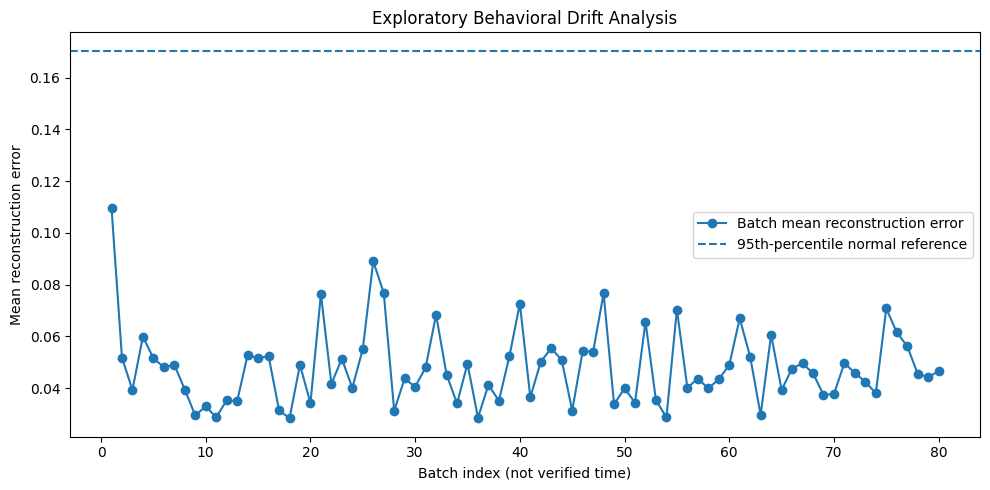

In [13]:

# STEP 11: Batch-level behavioral drift analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the reconstruction errors calculated in Step 10.
reference_limit = np.percentile(reference_errors, 95)

# Use the original Phase I threshold if available;
# otherwise use the 95th-percentile normal reference limit.
anomaly_threshold = (
    float(threshold)
    if "threshold" in globals()
    else float(reference_limit)
)

batch_size = 25
batch_rows = []

for start in range(0, len(test_errors), batch_size):
    end = min(start + batch_size, len(test_errors))
    scores = test_errors[start:end]

    batch_rows.append({
        "Batch": len(batch_rows) + 1,
        "Start_Index": start,
        "End_Index": end - 1,
        "Mean_Error": float(np.mean(scores)),
        "Median_Error": float(np.median(scores)),
        "Anomaly_Fraction": float(
            np.mean(scores > anomaly_threshold)
        )
    })

batch_results = pd.DataFrame(batch_rows)
batch_results["Drift_Alert"] = (
    batch_results["Mean_Error"] > reference_limit
).astype(int)

display(batch_results.round(4))

print("Normal reference limit:", round(reference_limit, 6))
print("Batches flagged:", int(batch_results["Drift_Alert"].sum()))
print("Total batches:", len(batch_results))

plt.figure(figsize=(10, 5))
plt.plot(
    batch_results["Batch"],
    batch_results["Mean_Error"],
    marker="o",
    label="Batch mean reconstruction error"
)
plt.axhline(
    reference_limit,
    linestyle="--",
    label="95th-percentile normal reference"
)
plt.xlabel("Batch index (not verified time)")
plt.ylabel("Mean reconstruction error")
plt.title("Exploratory Behavioral Drift Analysis")
plt.legend()
plt.tight_layout()
plt.show()

batch_results.to_csv(
    "/content/step11_batch_drift.csv",
    index=False
)


## Step 12: Controlled Synthetic Drift Experiment

This experiment tests whether the trained autoencoder responds to artificial changes in standardized sensor features. We apply shifts of different magnitudes to a fixed sample of normal validation records and measure the resulting reconstruction errors and anomaly flag rates.

The experiment provides a controlled sensitivity analysis. Since the shifts are artificially introduced, the findings cannot be interpreted as proof of real-world machine degradation or early-warning capability.

,Shift,Mean_Error,Median_Error,Flag_Rate
0,0.00,0.0455,0.0247,0.050
1,0.25,0.1155,0.0906,0.162
2,0.50,0.3262,0.2984,1.000
3,1.00,1.1748,1.1474,1.000
4,1.50,2.6037,2.5737,1.000
5,2.00,4.6230,4.5872,1.000


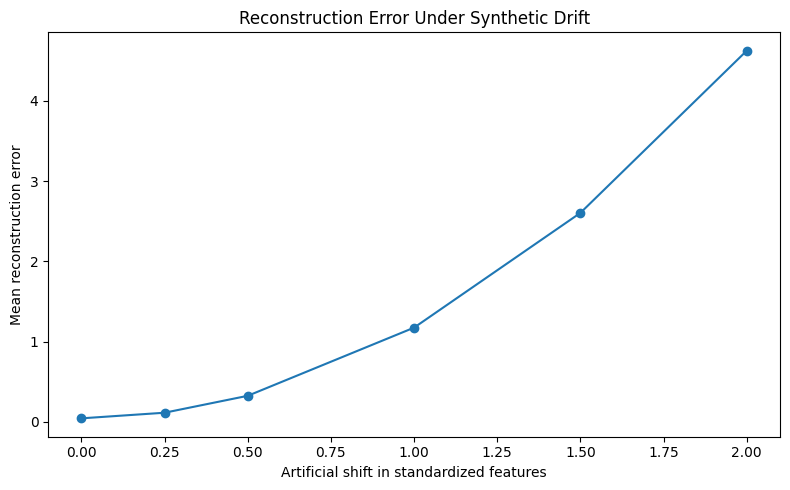

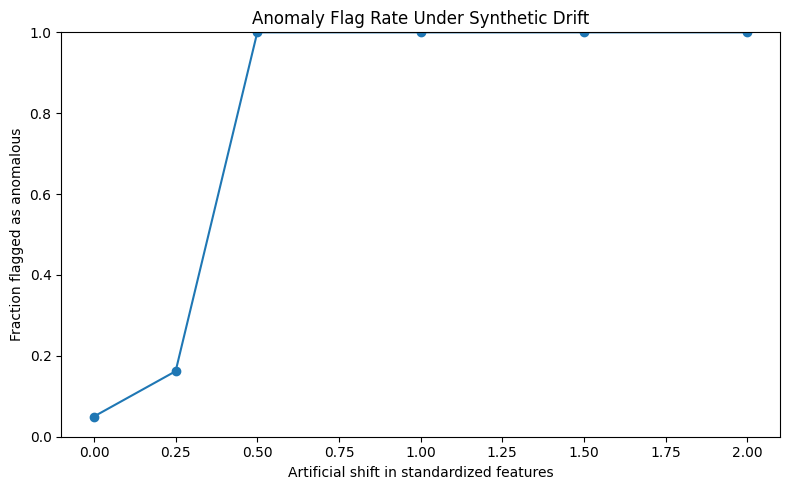

In [14]:

# STEP 12: Controlled synthetic drift experiment

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

sample_count = min(1000, len(X_reference))
indices = rng.choice(
    len(X_reference),
    size=sample_count,
    replace=False
)
X_base = X_reference[indices].copy()

shift_values = [0.0, 0.25, 0.5, 1.0, 1.5, 2.0]
drift_rows = []

for shift in shift_values:
    X_shifted = X_base.copy()

    if shift != 0:
        X_shifted += shift

    scores = get_reconstruction_errors(
        autoencoder, X_shifted
    )

    drift_rows.append({
        "Shift": shift,
        "Mean_Error": float(np.mean(scores)),
        "Median_Error": float(np.median(scores)),
        "Flag_Rate": float(
            np.mean(scores > anomaly_threshold)
        )
    })

synthetic_drift_results = pd.DataFrame(drift_rows)
display(synthetic_drift_results.round(4))

plt.figure(figsize=(8, 5))
plt.plot(
    synthetic_drift_results["Shift"],
    synthetic_drift_results["Mean_Error"],
    marker="o"
)
plt.xlabel("Artificial shift in standardized features")
plt.ylabel("Mean reconstruction error")
plt.title("Reconstruction Error Under Synthetic Drift")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(
    synthetic_drift_results["Shift"],
    synthetic_drift_results["Flag_Rate"],
    marker="o"
)
plt.xlabel("Artificial shift in standardized features")
plt.ylabel("Fraction flagged as anomalous")
plt.title("Anomaly Flag Rate Under Synthetic Drift")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

synthetic_drift_results.to_csv(
    "/content/step12_synthetic_drift.csv",
    index=False
)


## Step 13: Final Model Comparison and Experiment Export

In this step, we consolidate the baseline model results and export the experimental tables. The comparison will help identify which approach performs best on the selected evaluation metrics.

We will preserve the results of the existing baseline experiment rather than rerunning it. The saved outputs will support the final report and presentation. Conclusions will be limited to the measured results and will acknowledge the limitations of the dataset and the proxy failure labels.

In [15]:

# STEP 13: Export comparison and experiment results

import os
import pandas as pd

OUTPUT_DIR = "/content/behavioral_drift_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# baseline_results is the dataframe created in Step 9.
# Your screenshot shows this table was successfully generated.
if "baseline_results" in globals():
    baseline_results.to_csv(
        os.path.join(OUTPUT_DIR, "step9_baseline_comparison.csv"),
        index=False
    )
elif "results" in globals():
    pd.DataFrame(results).to_csv(
        os.path.join(OUTPUT_DIR, "step9_baseline_comparison.csv"),
        index=False
    )
else:
    print(
        "Baseline results variable not found. "
        "Save the Step 9 displayed table manually or rerun its cell."
    )

threshold_analysis.to_csv(
    os.path.join(OUTPUT_DIR, "step10_threshold_analysis.csv"),
    index=False
)

batch_results.to_csv(
    os.path.join(OUTPUT_DIR, "step11_batch_drift.csv"),
    index=False
)

synthetic_drift_results.to_csv(
    os.path.join(OUTPUT_DIR, "step12_synthetic_drift.csv"),
    index=False
)

test_predictions_df = pd.DataFrame({
    "Actual_Failure_Label": y_test_arr,
    "Reconstruction_Error": test_errors,
    "Predicted_Anomaly": (
        test_errors > anomaly_threshold
    ).astype(int)
})

test_predictions_df.to_csv(
    os.path.join(OUTPUT_DIR, "test_predictions.csv"),
    index=False
)

print("Exported files:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", filename)

# Download all outputs as a ZIP archive.
import shutil
zip_path = shutil.make_archive(
    "/content/behavioral_drift_results",
    "zip",
    OUTPUT_DIR
)

print("\nZIP archive:", zip_path)


Exported files:
- step10_threshold_analysis.csv
- step11_batch_drift.csv
- step12_synthetic_drift.csv
- step9_baseline_comparison.csv
- test_predictions.csv

ZIP archive: /content/behavioral_drift_results.zip


In [16]:
from google.colab import files
files.download("/content/behavioral_drift_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>